<a href="https://colab.research.google.com/github/islamsamian22-ship-it/Python-prohects/blob/main/KMeans_Cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape   : (200, 5)
Columns : ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40

Cluster
cluster0    81
cluster1    39
cluster2    22
cluster3    35
cluster4    23
Name: count, dtype: int64

Cluster centres 
   income  score
0   55.30  49.52
1   86.54  82.13
2   25.73  79.36
3   88.20  17.11
4   26.30  20.91



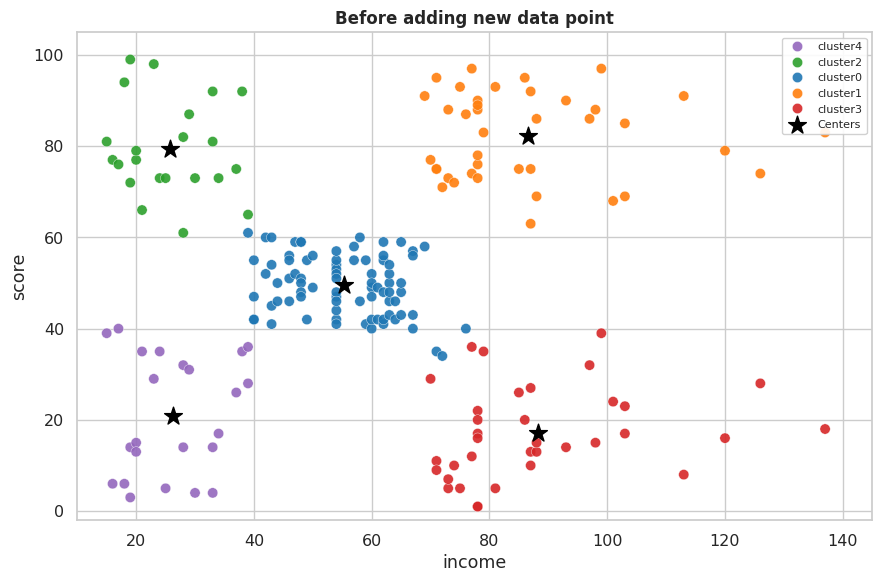

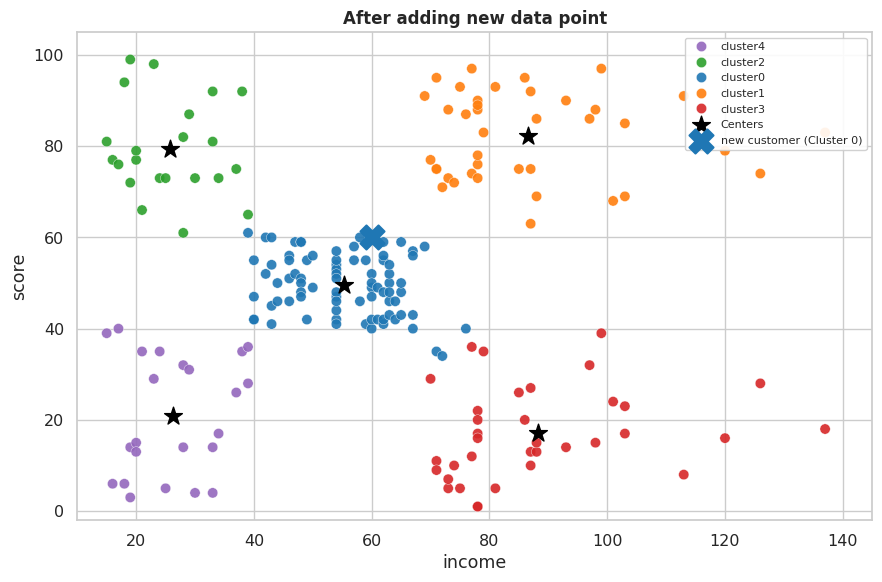

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.cluster import KMeans
from google.colab import drive
import os
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/mall_customers.csv')
print(f"Shape   : {df.shape}")
print(f"Columns : {list(df.columns)}")
print(df.head(5).to_string(index=False))
print()

features = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
features.columns = ["income", "score"]
K = 5
model = KMeans(n_clusters=K, n_init=10, random_state=42)
model.fit(features)

features = features.copy()
features["Cluster"] = ["cluster" + str(c) for c in model.predict(features)]

centers = pd.DataFrame(model.cluster_centers_, columns=["income", "score"])

print(features["Cluster"].value_counts().sort_index())
print()
print("Cluster centres ")
print(centers.round(2).to_string())
print()

PALETTE = {
    "cluster0": "#1f77b4",   # blue
    "cluster1": "#ff7f0e",   # orange
    "cluster2": "#2ca02c",   # green
    "cluster3": "#d62728",   # red
    "cluster4": "#9467bd",   # purple}


def draw_plot(ax, data, centers, title, new_point=None):
    """Draw the cluster scatter on a given axes."""


    sns.scatterplot(data=data, x="income", y="score", hue="Cluster", palette=PALETTE, s=55, alpha=0.90, edgecolor="white",
        linewidth=0.3, legend="full", ax=ax)

    ax.scatter(centers["income"], centers["score"], c="black", s=180, marker="*", zorder=6, label="Centers")

    if new_point is not None:
        ax.scatter(new_point["income"], new_point["score"], c="#1f77b4", s=300, marker="X", zorder=7, linewidths=1.5,
            label=f"new customer (Cluster {new_point['cluster_label']})")

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles=handles,
        labels=labels,
        title=None,
        fontsize=8,
        loc="upper right",
        framealpha=0.9)

    ax.set_title(title, fontweight="bold", fontsize=12)
    ax.set_xlabel("income")
    ax.set_ylabel("score")
    ax.set_xlim(10, 145)
    ax.set_ylim(-2, 105)


output_dir = '/content/outputs'
os.makedirs(output_dir, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
fig1, ax1 = plt.subplots(figsize=(9, 6))
draw_plot(ax1, features, centers, title="Before adding new data point")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "mall_before.png"), dpi=150)
plt.show()

new_customer = pd.DataFrame({"income": [60], "score": [60]})
predicted_cluster = model.predict(new_customer)[0]
new_point_info = {"income": 60,"score": 60,"cluster_label": predicted_cluster}



fig2, ax2 = plt.subplots(figsize=(9, 6))
draw_plot(ax2, features, centers,
          title="After adding new data point",
          new_point=new_point_info)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "mall_after.png"), dpi=150)
plt.show()

